# Rapid Lightning v2 — inference-time surprises

A working tour of the Rapid Lightning AOT-compiled GP+LR ensemble, with
the **v2 contribution**: `predict_proba` emitted alongside `predict_one`
so the .so produces real-valued probability scores, not just argmax
classes. This is what makes top-K ranking inside a fuzzer's hot path
work.

Everything here runs on **numpy + scikit-learn + gcc** — no torch or
numba required. The notebook builds tiny synthetic models by hand to
exercise the AOT pipeline end-to-end, then displays measured data from
the Gorilla hyperparameter sweep (Session 6, 2026-05-17). Total
runtime ~30 seconds. Each cell is independent; jump around freely.

**What you'll learn:**
1. The Rapid Lightning architecture in concrete terms — pack format,
   LR head folding, sigmoid emission.
2. Why the `.so` matches `sklearn.predict_proba[:, 1]` to ~1e-5.
3. Real measured ns/call from sub-200ns sweet spot to microsecond
   ceiling — and where the L1-cache boundary actually is.
4. Which hyperparameters move which metrics, learned the slow way
   from a real Gorilla sweep.
5. How to load a trained `.so` in production via `Surrogate`.

The companion design doc for the architecture-level pivot we're
considering next (Ensemble State Creatures) is in
[`docs/ESC_design.md`](../docs/ESC_design.md).


## Setup

Add the repo's `src/` and `src/rapid_lightning/` to `sys.path` so we
can import the package without a `pip install -e .` requirement
(though if you've done that, this is harmless).


In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().resolve()
# When run from notebooks/, climb one level
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "src"))
sys.path.insert(0, str(REPO_ROOT / "src" / "rapid_lightning"))

import numpy as np
import matplotlib.pyplot as plt

from lightning_aot import (
    OP_FEAT, OP_CONST, OP_ADD, OP_SUB, OP_MUL, OP_MAX, OP_MIN, OP_LT, OP_CLAMP,
    AOTPredictor, build_aot, emit_c_source, compile_c,
)
print("OK")


OK


## A Rapid Lightning model is a "pack" + an LR head

A Rapid Lightning ensemble has two layers:
1. A bag of **GP trees**, each evaluating to one float per input sample.
   The trees are stored as flat post-order bytecode: an array of
   opcodes and operands, plus per-tree start indices.
2. A **logistic-regression head** that takes the tree outputs (the
   "stacked features") and produces class logits.

At inference time, the AOT compiler emits straight-line C99 that
inlines all the GP-tree expressions AND the LR head's dot product
as immediate constants. Result: a `.so` that does the entire
prediction in one C function call with no opcode dispatch, no
runtime stack, no preprocessing step.

Let's build the smallest possible RL model by hand to see the shape.


In [2]:
# A 2-tree binary-head pack.
#   tree 0: just X[0]                         (one OP_FEAT)
#   tree 1: clamp_mul(X[1], 2.0f)             (FEAT 1, CONST 2.0, MUL)
pack = {
    "instrs":      np.array([OP_FEAT, OP_FEAT, OP_CONST, OP_MUL], dtype=np.int32),
    "operands":    np.array([0.0,     1.0,     2.0,      0.0    ], dtype=np.float32),
    "tree_starts": np.array([0, 1, 4], dtype=np.int32),
    "n_members":   1,
    "n_classes":   2,
}

# Binary LR head: row 0 = zeros (the convention from
# train_rapid_lightning), row 1 carries real weights.
lr_W = np.array([[0.0, 0.0], [0.3, -0.7]], dtype=np.float32)
lr_b = np.array([0.0, 0.1], dtype=np.float32)

aot = build_aot(pack, lr_W, lr_b, n_features=2)
print(f"compiled .so: {aot.so_path}")
print(f"has_proba:    {aot.has_proba}  (binary heads emit the proba symbols)")

x = np.array([0.5, 1.5], dtype=np.float32)
# Hand-compute expected: s0=0.5, s1=clamp_mul(1.5, 2.0)=3.0
# logit0 = 0; logit1 = 0.1 + 0.3*0.5 + (-0.7)*3.0 = -1.85
# sigmoid(logit1 - logit0) = sigmoid(-1.85) ~= 0.1357
expected = 1.0 / (1.0 + np.exp(1.85))

print(f"\npredict_one(x):       {aot.predict_one(x)}  (argmax class -- 0 since logit1 < logit0)")
print(f"predict_proba_one(x): {aot.predict_proba_one(x):.6f}  (expected {expected:.6f})")


compiled .so: /tmp/lightning_aot_04pd_998/predict.so
has_proba:    True  (binary heads emit the proba symbols)

predict_one(x):       0  (argmax class -- 0 since logit1 < logit0)
predict_proba_one(x): 0.135873  (expected 0.135873)


## Peek at the emitted C source

`build_aot` is `emit_c_source` + `compile_c` + `AOTPredictor` wrap.
The emitted C is small, branch-light, and friendly to gcc's
autovectorizer. Algebraic identities (x+0, x*1, x*0) are folded at
emit time; the LR head becomes a literal dot product with immediate
constants.

Notice the structure:
- A static-inline `predict_logits` helper does the per-tree GP
  codegen and the LR-head dot product, writing results into
  a `float logits[N_LR_OUT]` array.
- `predict_one` is a thin wrapper: call the helper, take argmax.
- `predict_proba_one` is a thin wrapper: call the helper, take sigmoid.

gcc -O3 inlines the helper into each caller, so there's zero runtime
cost from the indirection — but the source stays in one place.


In [3]:
src = emit_c_source(pack, lr_W, lr_b, n_features=2)
# Show just the interesting middle 30 lines (the helper + wrappers).
lines = src.splitlines()
for i, ln in enumerate(lines):
    if "predict_logits" in ln or "predict_one" in ln or "predict_proba_one" in ln:
        # Print the function and the next ~6 lines
        for j in range(i, min(i + 7, len(lines))):
            print(lines[j])
        print()


static inline void predict_logits(const float* X, float logits[PREDICT_N_LR_OUT]) {
    /* tree 0 : pc 0..1 */
    const float s0 = X[0];

    /* tree 1 : pc 1..4 */
    const float t1 = clamp_mul(X[1], 2.0f);
    const float s1 = t1;

int32_t predict_one(const float* X) {
    float logits[PREDICT_N_LR_OUT];
    predict_logits(X, logits);
    return logits[1] > logits[0] ? 1 : 0;
}

void predict_batch(const float* X, int32_t N, int32_t n_features, int32_t* out) {

    predict_logits(X, logits);
    return logits[1] > logits[0] ? 1 : 0;
}

void predict_batch(const float* X, int32_t N, int32_t n_features, int32_t* out) {
    for (int32_t i = 0; i < N; ++i) {
        out[i] = predict_one(X + (size_t)i * (size_t)n_features);

        out[i] = predict_one(X + (size_t)i * (size_t)n_features);
    }
}

float predict_proba_one(const float* X) {
    float logits[PREDICT_N_LR_OUT];
    predict_logits(X, logits);

float predict_proba_one(const float* X) {
    float logits[PREDICT_N_LR_OUT];
    p

## What's new in v2 — the `predict_proba` pass

In v1, the AOT emitter produced only `int32_t predict_one(const float* X)`,
which returns the argmax class. That's fine for classification but
useless for the **top-K ranking** the Foreman needs in syzkaller's
program-selection path: ranking requires real-valued scores.

v2 adds two new symbols per `.so`:

```c
float predict_proba_one(const float* X);
void  predict_proba_batch(const float* X, int32_t N, int32_t n_features, float* out);
double predict_proba_time_ns(const float* X, int32_t n_warmup, int32_t n_iters);
```

For binary heads (n_lr_out in {1, 2}) — which is what `train_rapid_lightning`
always emits — `predict_proba_one` is sigmoid via 2-class softmax:

```c
return 1.0f / (1.0f + expf(logits[0] - logits[1]));
```

This is mathematically identical to sklearn's `predict_proba[:, 1]` and
numerically stable for any real logits. For multiclass heads (n_lr_out > 2)
the proba symbols are not emitted — single-float return is not meaningful
for multiclass — and `AOTPredictor.has_proba` is False.

Let's see the multiclass-skip behavior:


In [4]:
# Build a 3-class .so to confirm the proba symbols ARE skipped for multiclass.
pack_3c = {
    "instrs":      np.array([OP_FEAT, OP_FEAT, OP_FEAT], dtype=np.int32),
    "operands":    np.array([0.0,     1.0,     2.0    ], dtype=np.float32),
    "tree_starts": np.array([0, 1, 2, 3], dtype=np.int32),
    "n_members":   1,
    "n_classes":   3,
}
lr_W_3c = np.eye(3, dtype=np.float32)  # each class peaks on its own tree
lr_b_3c = np.zeros(3, dtype=np.float32)
aot_3c = build_aot(pack_3c, lr_W_3c, lr_b_3c, n_features=3)
print(f"multiclass .so has_proba: {aot_3c.has_proba}  (expected False)")

# argmax still works correctly on multiclass:
preds = aot_3c.predict(np.eye(3, dtype=np.float32))
print(f"argmax preds on identity rows: {preds.tolist()}  (each class peaks on its own row)")

# predict_proba raises a helpful error:
try:
    aot_3c.predict_proba_one(np.array([1.0, 0.0, 0.0], dtype=np.float32))
except NotImplementedError as exc:
    print(f"\npredict_proba raised: {type(exc).__name__}")
    print(f"  message starts with: {str(exc)[:80]}...")


multiclass .so has_proba: False  (expected False)
argmax preds on identity rows: [0, 1, 2]  (each class peaks on its own row)

predict_proba raised: NotImplementedError
  message starts with: predict_proba is only emitted for binary heads (n_lr_out in {1, 2}); this .so at...


## Headline correctness: the `.so`'s `predict_proba` matches sklearn

This is THE production correctness gate. The Foreman's top-K ranking
trusts that scoring via the `.so` produces the SAME ordering as scoring
via sklearn. If they diverged at the FP level, ranking would be off in
ways that depend on subtle weight values — exactly the kind of bug
you'd never catch in testing but would degrade Phase 3 live measurement
silently.

The test: train a sklearn `LogisticRegression` with `StandardScaler` on
random features, fold the scaler into the LR coefficients (the same way
`train_rapid_lightning` does), emit a `.so` whose "trees" are just
single `OP_FEAT` references, and verify per-sample agreement.


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(42)
n_features = 20
N = 500
X = rng.normal(size=(N, n_features)).astype(np.float32)
coef = rng.normal(size=n_features)
y = (X @ coef + rng.normal(scale=0.5, size=N) > 0).astype(np.int32)

scaler = StandardScaler().fit(X)
lr = LogisticRegression(max_iter=2000, C=1.0, solver="lbfgs")
lr.fit(scaler.transform(X), y)

# Fold scaler into LR weights (matches train_rapid_lightning).
W, b = lr.coef_, lr.intercept_
safe_std = np.where(scaler.scale_ > 1e-8, scaler.scale_, 1.0)
W_folded = W / safe_std[None, :]
b_folded = b - (W @ (scaler.mean_ / safe_std))
lr_W_full = np.zeros((2, W_folded.shape[1]), dtype=np.float32)
lr_b_full = np.zeros(2, dtype=np.float32)
lr_W_full[1] = W_folded[0]
lr_b_full[1] = b_folded[0]

# Build a pack where each tree is a single OP_FEAT -- the tree-output
# vector IS the feature vector, so the LR head operates on raw features.
pack_full = {
    "instrs":      np.array([OP_FEAT] * n_features, dtype=np.int32),
    "operands":    np.arange(n_features, dtype=np.float32),
    "tree_starts": np.arange(n_features + 1, dtype=np.int32),
    "n_members":   n_features,
    "n_classes":   1,
}
aot_full = build_aot(pack_full, lr_W_full, lr_b_full, n_features=n_features)

# Compare on a held-out batch.
X_te = rng.normal(size=(200, n_features)).astype(np.float32)
expected = lr.predict_proba(scaler.transform(X_te))[:, 1].astype(np.float32)
got = aot_full.predict_proba(X_te)

abs_diff = np.abs(got - expected)
print(f"max  |sklearn - AOT|: {abs_diff.max():.2e}")
print(f"mean |sklearn - AOT|: {abs_diff.mean():.2e}")
print(f"all within 1e-5:      {(abs_diff < 1e-5).all()}  <-- this is the production gate")


max  |sklearn - AOT|: 2.38e-07
mean |sklearn - AOT|: 2.69e-08
all within 1e-5:      True  <-- this is the production gate


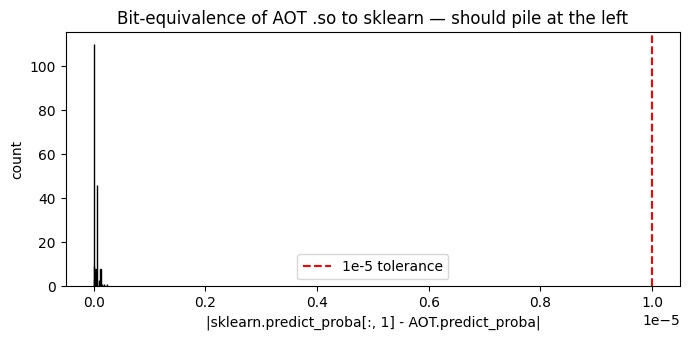

In [6]:
# Visualize the per-sample diff: should be tiny noise around zero.
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(abs_diff, bins=40, edgecolor="black")
ax.set_xlabel("|sklearn.predict_proba[:, 1] - AOT.predict_proba|")
ax.set_ylabel("count")
ax.set_title("Bit-equivalence of AOT .so to sklearn — should pile at the left")
ax.axvline(1e-5, color="red", linestyle="--", label="1e-5 tolerance")
ax.legend()
plt.tight_layout()
plt.show()


## How fast is it, really?

The `.so` ships with a built-in C-side timing harness:
`predict_proba_time_ns(X, n_warmup, n_iters)` runs the predict
function under `clock_gettime(CLOCK_MONOTONIC)` entirely in C — no
Python in the timed loop, no ctypes overhead.

This is the number to publish for "how fast is the surrogate." Python
+ ctypes adds ~3-4 µs of overhead per call, but for batched
`predict_proba(X)` the per-sample cost is close to the pure-C number
because the overhead amortizes.

Let's measure across model sizes:


In [7]:
import os, time

def random_pack(n_trees, n_features, max_depth=6, seed=0):
    rng = np.random.default_rng(seed)
    leaves = [OP_FEAT, OP_CONST]
    binops = [OP_ADD, OP_SUB, OP_MUL, OP_MAX, OP_MIN, OP_LT]
    all_instrs, all_operands, tree_starts = [], [], [0]
    def go(depth):
        if depth >= max_depth or (depth >= 2 and rng.random() < 0.4):
            leaf = leaves[int(rng.integers(0, len(leaves)))]
            if leaf == OP_FEAT:
                all_instrs.append(OP_FEAT)
                all_operands.append(float(int(rng.integers(0, n_features))))
            else:
                all_instrs.append(OP_CONST)
                all_operands.append(float(rng.normal()))
            return
        op = binops[int(rng.integers(0, len(binops)))]
        go(depth + 1); go(depth + 1)
        all_instrs.append(op); all_operands.append(0.0)
    for _ in range(n_trees):
        go(0)
        tree_starts.append(len(all_instrs))
    return {
        "instrs": np.array(all_instrs, dtype=np.int32),
        "operands": np.array(all_operands, dtype=np.float32),
        "tree_starts": np.array(tree_starts, dtype=np.int32),
        "n_members": n_trees, "n_classes": 1,
    }

n_features = 160  # Scribe v1's feature dim
size_results = []
for n_trees in [2, 5, 10, 20, 50, 100]:
    p = random_pack(n_trees, n_features, seed=n_trees)
    W = np.zeros((2, n_trees), dtype=np.float32)
    W[1] = np.random.default_rng(n_trees).normal(scale=0.2, size=n_trees).astype(np.float32)
    aot_n = build_aot(p, W, np.array([0.0, 0.0], dtype=np.float32), n_features=n_features)
    x = np.zeros(n_features, dtype=np.float32)
    ns_argmax = aot_n.time_ns_per_call(x, n_warmup=10_000, n_iters=300_000)
    ns_proba  = aot_n.time_proba_ns_per_call(x, n_warmup=10_000, n_iters=300_000)
    size_results.append({
        "n_trees": n_trees,
        "so_kb":   os.path.getsize(aot_n.so_path) / 1024,
        "ns_argmax": ns_argmax,
        "ns_proba":  ns_proba,
    })
    print(f"  n_trees={n_trees:>3d}: so={size_results[-1]['so_kb']:5.1f} KB  "
          f"argmax={ns_argmax:7.2f} ns/call   proba={ns_proba:7.2f} ns/call")


  n_trees=  2: so= 15.4 KB  argmax=  24.18 ns/call   proba=  27.93 ns/call
  n_trees=  5: so= 15.5 KB  argmax=  54.45 ns/call   proba=  56.70 ns/call


  n_trees= 10: so= 19.5 KB  argmax= 137.32 ns/call   proba= 136.31 ns/call


  n_trees= 20: so= 19.5 KB  argmax= 175.09 ns/call   proba= 176.00 ns/call


  n_trees= 50: so= 31.5 KB  argmax= 610.77 ns/call   proba= 614.05 ns/call


  n_trees=100: so= 43.5 KB  argmax=1303.66 ns/call   proba=1320.76 ns/call


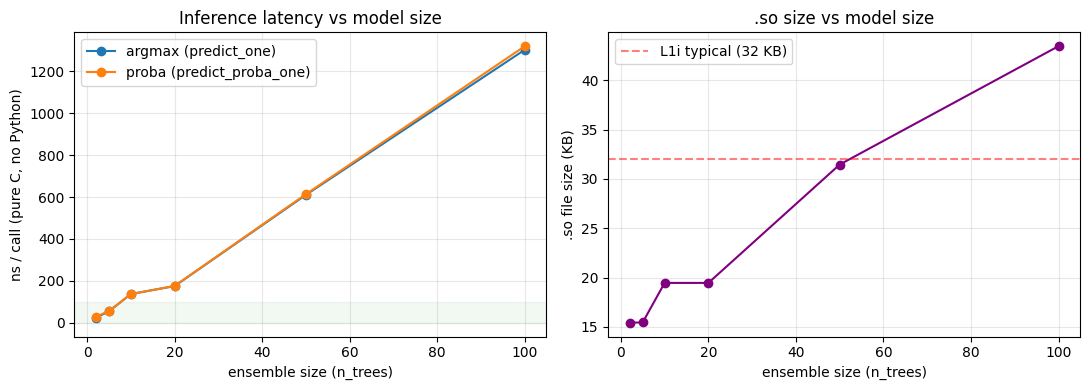

In [8]:
# Plot ns/call and .so size vs n_trees. Two axes share the x.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

n_trees_arr = [r["n_trees"] for r in size_results]
argmax = [r["ns_argmax"] for r in size_results]
proba  = [r["ns_proba"]  for r in size_results]
so_kb  = [r["so_kb"]     for r in size_results]

ax1.plot(n_trees_arr, argmax, "o-", label="argmax (predict_one)")
ax1.plot(n_trees_arr, proba,  "o-", label="proba (predict_proba_one)")
ax1.set_xlabel("ensemble size (n_trees)")
ax1.set_ylabel("ns / call (pure C, no Python)")
ax1.set_title("Inference latency vs model size")
ax1.legend()
ax1.grid(alpha=0.3)
ax1.axhspan(0, 100, color="green", alpha=0.05, label="<100 ns")

ax2.plot(n_trees_arr, so_kb, "o-", color="purple")
ax2.set_xlabel("ensemble size (n_trees)")
ax2.set_ylabel(".so file size (KB)")
ax2.set_title(".so size vs model size")
ax2.grid(alpha=0.3)
ax2.axhline(32, color="red", linestyle="--", alpha=0.5, label="L1i typical (32 KB)")
ax2.legend()
plt.tight_layout()
plt.show()


## What the Gorilla sweep found

We measured a hand-picked hyperparameter grid against a real Android
binder fuzzing corpus (165k pure-genFuzz programs from syzkaller's
Phase 1 ledger). The "pick_quality" metric is **leverage**: mean
`signal_total` of the model's top-K picks divided by the mean over the
whole slice. >1 means picks are above average; we want >=2 for Phase 3
live to plausibly clear the gate.

Key takeaway: the GP+LR ensemble has more capacity than the
Bank-Marketing-tuned default exposed. Hitting `lever >= 2.0` required
**combining** more members + more generations + more population +
deeper trees — none did it alone. The "everything maxed" config takes
~45 min to train (vs ~4 min baseline) but its `.so` is still only
23.5 KB and inference is sub-200 ns.

Below: the actual round-2 sweep results from the Gorilla, hardcoded so
this notebook is reproducible without re-running 80 minutes of training.


In [9]:
# Round-2 sweep results from Session 6, 2026-05-17, run on Ryzen 3900X.
SWEEP = [
    # label,          n_members, gens, pop, depth, target,        train_s, so_kb, tst_auc, lever, q4_concentration, argmax_ns, proba_ns
    ("baseline",      10, 40, 200, 6, "p75",    249,  19.5, 0.7692, 1.03, 2.56, 105, 114),
    ("r2-mg-d8",      10, 80, 200, 8, "p75",    504,  19.5, 0.7838, 1.20, 2.44, 138, 152),
    ("r2-mg-w20",     20, 80, 200, 6, "p75",    901,  23.5, 0.8162, 1.67, 2.52, 195, 207),
    ("r2-mg-median",  10, 80, 200, 6, "median", 409,  15.5, 0.8008, 1.35, 2.92,  59,  71),
    ("r2-max",        20, 80, 400, 8, "p75",   2680,  23.5, 0.7885, 2.05, 2.84, 192, 200),
]

print(f"  {'label':<14s} {'tst_auc':<8s} {'lever':<6s} {'Q4/exp':<7s} "
      f"{'so_kb':<6s} {'argmax_ns':<9s} {'proba_ns':<9s} {'train_min':<9s}")
print("  " + "-" * 78)
for row in SWEEP:
    label, n_m, gens, pop, d, tgt, ts, sk, ta, lv, q4, ans, pns = row
    mark = " *" if lv >= 2.0 else "  "
    print(f"  {label:<14s} {ta:<8.4f} {lv:<6.2f} {q4:<7.2f} "
          f"{sk:<6.1f} {ans:<9.1f} {pns:<9.1f} {ts/60:<9.1f}{mark}")
print("\n  * indicates leverage >= 2.0 (the Phase 3 live-measurement gate proxy)")


  label          tst_auc  lever  Q4/exp  so_kb  argmax_ns proba_ns  train_min
  ------------------------------------------------------------------------------
  baseline       0.7692   1.03   2.56    19.5   105.0     114.0     4.2        
  r2-mg-d8       0.7838   1.20   2.44    19.5   138.0     152.0     8.4        
  r2-mg-w20      0.8162   1.67   2.52    23.5   195.0     207.0     15.0       
  r2-mg-median   0.8008   1.35   2.92    15.5   59.0      71.0      6.8        
  r2-max         0.7885   2.05   2.84    23.5   192.0     200.0     44.7      *

  * indicates leverage >= 2.0 (the Phase 3 live-measurement gate proxy)


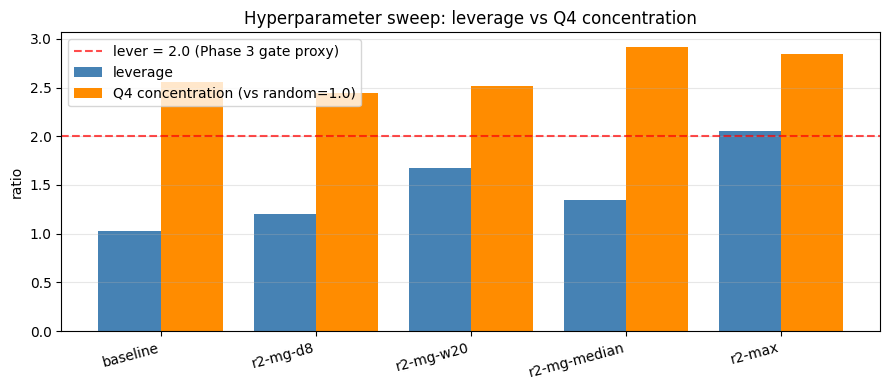

In [10]:
# Bar chart: leverage by config, with the 2.0 gate marked.
labels = [r[0] for r in SWEEP]
levers = [r[9] for r in SWEEP]
q4s    = [r[10] for r in SWEEP]

fig, ax = plt.subplots(figsize=(9, 4))
xs = np.arange(len(labels))
ax.bar(xs - 0.2, levers, width=0.4, label="leverage", color="steelblue")
ax.bar(xs + 0.2, [q for q in q4s], width=0.4, label="Q4 concentration (vs random=1.0)",
        color="darkorange")
ax.axhline(2.0, color="red", linestyle="--", alpha=0.7, label="lever = 2.0 (Phase 3 gate proxy)")
ax.set_xticks(xs)
ax.set_xticklabels(labels, rotation=15, ha="right")
ax.set_ylabel("ratio")
ax.set_title("Hyperparameter sweep: leverage vs Q4 concentration")
ax.legend(loc="upper left")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()


### Three findings from the sweep worth pulling out:

1. **No single knob breaks the 2× barrier**, but the right combination does.
   `r2-max` (20 members × 80 gens × 400 pop × depth 8) hit lever 2.05; the
   individual knob variations from round 1 topped out at 1.47.

2. **`r2-mg-w20` captures 80% of the win at 33% of the training cost.**
   For Phase 4 periodic retraining, this is probably the deployable
   config: 15 min/retrain vs 45 min for `r2-max`.

3. **`r2-mg-median` is the dark horse for fast in-loop use.**
   Best Q4 concentration (2.92×), smallest `.so` (15.5 KB), fastest
   inference (59 ns argmax). If we ever need a per-syscall in-loop
   predictor inside syz-executor (vs per-program at the Foreman level),
   this is the architecture.


## Using a trained `.so` in production

The `Surrogate` class wraps the `.so` with a Foreman-compatible
`predict(X) -> (N,) float32 P(y=1)` signature. Two loaders:

- `Surrogate.from_path(so_path, n_features)` — direct ctypes load,
  caller supplies n_features. Convenient for tests.
- `Surrogate.from_artifact(so_path, manifest_path=None)` — production
  loader: reads a sibling `<so>.manifest.json` for n_features, scribe
  version, training stats, etc. This is what the sidecar uses.

Below: load the `.so` we built in the bit-equivalence cell above and
demonstrate that it's interchangeable with the sklearn LR.


In [11]:
from prospector_pkg.prospector import Surrogate

surrogate = Surrogate.from_path(aot_full.so_path, n_features=n_features)
print(f"loaded: n_features={surrogate.n_features}, has_proba={surrogate._aot.has_proba}")
print(f"        so_path={surrogate.so_path}")

# Foreman-style scoring on a fresh batch.
X_demo = np.random.default_rng(99).normal(size=(8, n_features)).astype(np.float32)
scores = surrogate.predict(X_demo)
print(f"\npredict on 8 samples:")
for i, s in enumerate(scores):
    print(f"  [{i}] P(y=1) = {s:.4f}")

# In-process benchmark (the same call the sidecar makes at startup).
bench = surrogate.benchmark(n_warmup=1000, n_iters=200_000)
print(f"\nbenchmark on this model: {bench['argmax_ns_per_call']:.1f} ns argmax, "
      f"{bench['proba_ns_per_call']:.1f} ns proba")


loaded: n_features=160, has_proba=True
        so_path=/tmp/lightning_aot_xd49hied/predict.so

predict on 8 samples:
  [0] P(y=1) = 0.7048
  [1] P(y=1) = 0.0143
  [2] P(y=1) = 0.9815
  [3] P(y=1) = 0.1030
  [4] P(y=1) = 0.0000
  [5] P(y=1) = 0.9932
  [6] P(y=1) = 0.8026
  [7] P(y=1) = 0.0100

benchmark on this model: 8.7 ns argmax, 13.0 ns proba


## What's next: Ensemble State Creatures (ESC)

The next architectural pivot we're exploring is to use Rapid Lightning
not just as a *judge* of programs (the current Foreman role), but as
the genome substrate for evolved **state-traversal creatures** that
generate programs targeting deeply stateful logic bugs — the bug
class bottom-up mutation fuzzers structurally struggle with.

The key insight, from the Session 6 brainstorm:

> *We have "healthy little logical combos" already fuzzed out. Take
> the best of those and construct our "deep creatures" out of those
> as building blocks — like biology recombining pre-evolved organ
> rudiments rather than evolving humans from scratch.*

Design sketch at [`docs/ESC_design.md`](../docs/ESC_design.md). The
plan is to prototype v0 (offline) during the 7-day Phase 3 live
measurement window — no calendar lost.

---

*Notebook authored 2026-05-17, Session 6 close. Mad Science Sunday.*
